In [66]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tabulate import tabulate

In [67]:
def f(t):
    return np.cos(t)

In [68]:
while True:
    try:
        x=float(input("Ingrese el valor para x: "))
        break
    except:
        print("Ingrese un número real")

while True:
    try:
        nodos=int(input("Ingrese el número de nodos a utilizar: "))
        break
    except:
        print("Ingrese un número entero")

Ingrese el valor para x:  .45
Ingrese el número de nodos a utilizar:  .3


Ingrese un número entero


Ingrese el número de nodos a utilizar:  .5


Ingrese un número entero


Ingrese el número de nodos a utilizar:  .9


Ingrese un número entero


Ingrese el número de nodos a utilizar:  3


In [69]:
vector_nodos=[]
for i in range(nodos):
    while True:
        try:
            vector_nodos.append(float(input(f"Ingrese el valor del nodo x{i}: ")))
            break
        except:
            print("Ingrese un número real")

Ingrese el valor del nodo x0:  .3
Ingrese el valor del nodo x1:  .5
Ingrese el valor del nodo x2:  .9


In [70]:
matriz=[]
for i in range(nodos):
    matriz.append([])
for i in range(nodos):
    for j in range(nodos):
        if j==0:
            matriz[i].append(float(f(vector_nodos[i])))
        elif j>0:
            if i<j:
                matriz[i].append(0)
            else:
                matriz[i].append(((x- vector_nodos[i-j])*matriz[i][j-1]-(x- vector_nodos[i])*matriz[i-1][j-1])/(vector_nodos[i]-vector_nodos[i-j]))

In [71]:
matrizfinal=[]
for i in range(nodos):
    matrizfinal.append([])
for i in range(nodos):
    for j in range(nodos+1):
        if j==0:
            matrizfinal[i].append(vector_nodos[i])
        else:
            matrizfinal[i].append(matriz[i][j-1])

In [72]:
cabecera=[]
for i in range(nodos+1):
    if i==0:
        cabecera.append("xi")
    else:
        cabecera.append(f"y{i-1}")
df = pd.DataFrame(matrizfinal)
print(tabulate(df, headers=cabecera, tablefmt='fancy_grid', showindex=False))

╒══════╤══════════╤══════════╤══════════╕
│   xi │       y0 │       y1 │       y2 │
╞══════╪══════════╪══════════╪══════════╡
│  0.3 │ 0.955336 │ 0        │ 0        │
├──────┼──────────┼──────────┼──────────┤
│  0.5 │ 0.877583 │ 0.897021 │ 0        │
├──────┼──────────┼──────────┼──────────┤
│  0.9 │ 0.62161  │ 0.909579 │ 0.900161 │
╘══════╧══════════╧══════════╧══════════╛


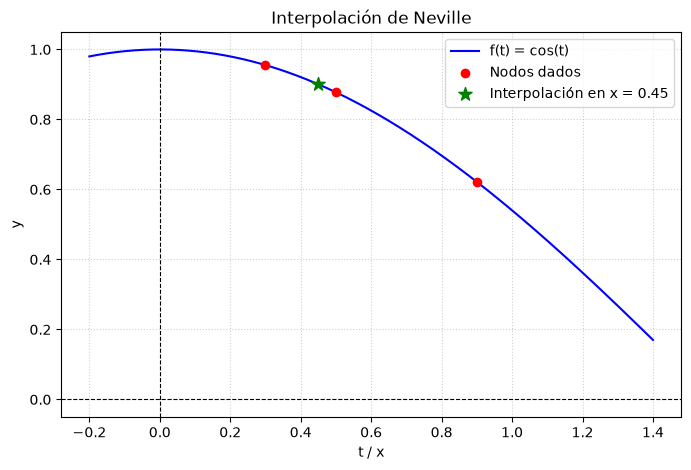


El valor interpolado para x = 0.45 es: 0.9001605667975947


In [73]:
#Esta parte la hizo Gemini
# Generar puntos para graficar la función original de forma continua
t_vals = np.linspace(min(vector_nodos) - 0.5, max(vector_nodos) + 0.5, 500)
y_vals = f(t_vals)

plt.figure(figsize=(8, 5))

# 1. Curva de la función original
plt.plot(t_vals, y_vals, label="f(t) = cos(t)", color="blue", linestyle="-")

# 2. Puntos de los nodos utilizados
plt.scatter(vector_nodos, [f(n) for n in vector_nodos], color="red", zorder=5, label="Nodos dados")

# 3. Valor interpolado calculado (último elemento de la diagonal de la matriz de Neville)
resultado_interpolado = matriz[nodos - 1][nodos - 1]
plt.scatter([x], [resultado_interpolado], color="green", s=100, zorder=6, marker="*", label=f"Interpolación en x = {x}")

# Detalles de la gráfica
plt.title("Interpolación de Neville")
plt.xlabel("t / x")
plt.ylabel("y")
plt.axhline(0, color="black", linewidth=0.8, linestyle="--")
plt.axvline(0, color="black", linewidth=0.8, linestyle="--")
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend()

# Mostrar la gráfica
plt.show()

# Imprimir el resultado final de forma clara en consola
print(f"\nEl valor interpolado para x = {x} es: {resultado_interpolado}")